# Monte Carlo option pricing

Pricing European options with the Black-Scholes formula and then by Monte Carlo simulation of the stock price, to see how the simulation converges and how to make it converge faster. Then using the same simulation for options that don't have a simple formula (Asian and barrier options), and estimating the Greeks.

In [1]:
# import packages

import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm

np.random.seed(42)

## The model

Under the risk-neutral measure the stock follows geometric Brownian motion:

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t$$

which has the exact solution

$$S_T = S_0 \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right), \qquad Z \sim N(0,1)$$

The price of an option is the discounted expected payoff, $V_0 = e^{-rT}\,\mathbb{E}[\text{payoff}]$.

I use Apple (AAPL) for a real starting price and volatility: the spot is the last close of 2024 and $\sigma$ is the annualised standard deviation of daily log returns over 2024.

In [2]:
# Download one year of Apple prices
data = yf.download('AAPL', start='2024-01-01', end='2025-01-01', auto_adjust=True, progress=False)['Close']['AAPL']

log_returns = np.log(data / data.shift(1)).dropna()

S0 = float(data.iloc[-1])
sigma = float(log_returns.std() * np.sqrt(252))  # annualised volatility

print('Spot price S0:', round(S0, 2))
print('Historical volatility:', round(sigma, 4))

Spot price S0: 248.62
Historical volatility: 0.2232


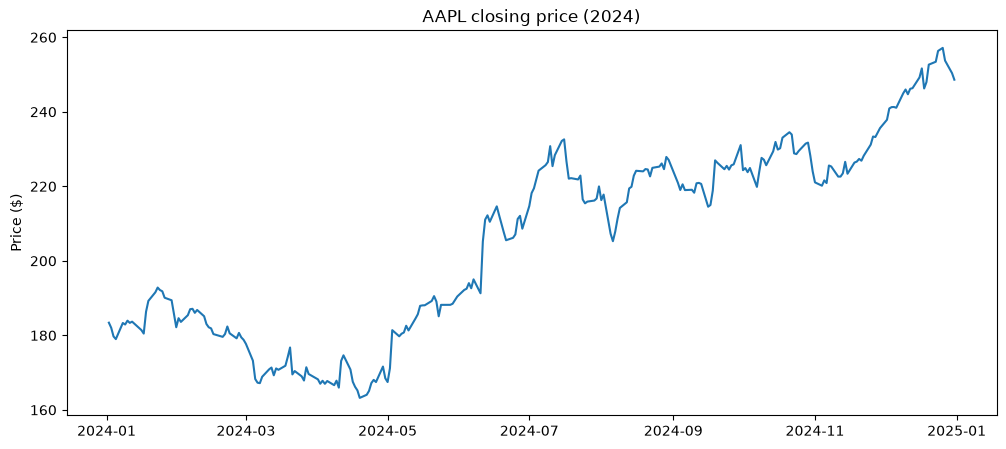

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(data.index, data)
plt.title('AAPL closing price (2024)')
plt.ylabel('Price ($)')
plt.show()

In [4]:
# Option parameters
K = 250       # strike (close to the money)
T = 1.0       # one year to expiry
r = 0.04      # risk-free rate (assumed)

## 1. Black-Scholes closed form

$$C = S_0 N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0 N(-d_1)$$

$$d_1 = \frac{\ln(S_0/K) + (r + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

where $N$ is the standard normal CDF.

In [5]:
def d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2

def bs_call(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def bs_put(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [6]:
call_bs = bs_call(S0, K, T, r, sigma)
put_bs = bs_put(S0, K, T, r, sigma)

print('Black-Scholes call:', round(call_bs, 4))
print('Black-Scholes put: ', round(put_bs, 4))

Black-Scholes call: 26.1877
Black-Scholes put:  17.7693


### Put-call parity

For European options on a non-dividend stock, holding a call and selling a put is the same as holding the stock and borrowing the discounted strike:

$$C - P = S_0 - K e^{-rT}$$

In [7]:
lhs = call_bs - put_bs
rhs = S0 - K * np.exp(-r * T)
print('C - P:          ', lhs)
print('S0 - K*exp(-rT):', rhs)
print('Difference:     ', abs(lhs - rhs))

# Check it across a range of strikes too
strikes = np.linspace(150, 350, 41)
parity_error = (bs_call(S0, strikes, T, r, sigma) - bs_put(S0, strikes, T, r, sigma)) - (S0 - strikes * np.exp(-r * T))
print('Max parity error over 41 strikes:', np.max(np.abs(parity_error)))

C - P:           8.418423903325433
S0 - K*exp(-rT): 8.418423903325447
Difference:      1.4210854715202004e-14
Max parity error over 41 strikes: 5.684341886080802e-14


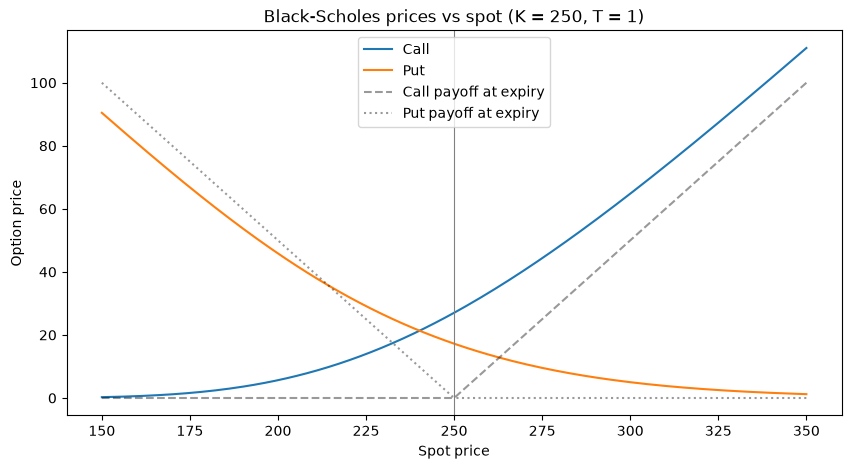

In [8]:
spots = np.linspace(150, 350, 200)

plt.figure(figsize=(10, 5))
plt.plot(spots, bs_call(spots, K, T, r, sigma), label='Call')
plt.plot(spots, bs_put(spots, K, T, r, sigma), label='Put')
plt.plot(spots, np.maximum(spots - K, 0), 'k--', alpha=0.4, label='Call payoff at expiry')
plt.plot(spots, np.maximum(K - spots, 0), 'k:', alpha=0.4, label='Put payoff at expiry')
plt.axvline(K, color='grey', linewidth=0.8)
plt.title('Black-Scholes prices vs spot (K = 250, T = 1)')
plt.xlabel('Spot price')
plt.ylabel('Option price')
plt.legend()
plt.show()

## 2. Simulating geometric Brownian motion

To simulate whole paths I split $[0, T]$ into $n$ steps of size $\Delta t = T/n$ and use the exact update

$$S_{t+\Delta t} = S_t \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z\right)$$

In [9]:
def simulate_gbm(S0, r, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    Z = np.random.standard_normal((n_paths, n_steps))
    increments = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    log_paths = np.cumsum(increments, axis=1)
    log_paths = np.hstack([np.zeros((n_paths, 1)), log_paths])  # start every path at S0
    return S0 * np.exp(log_paths)

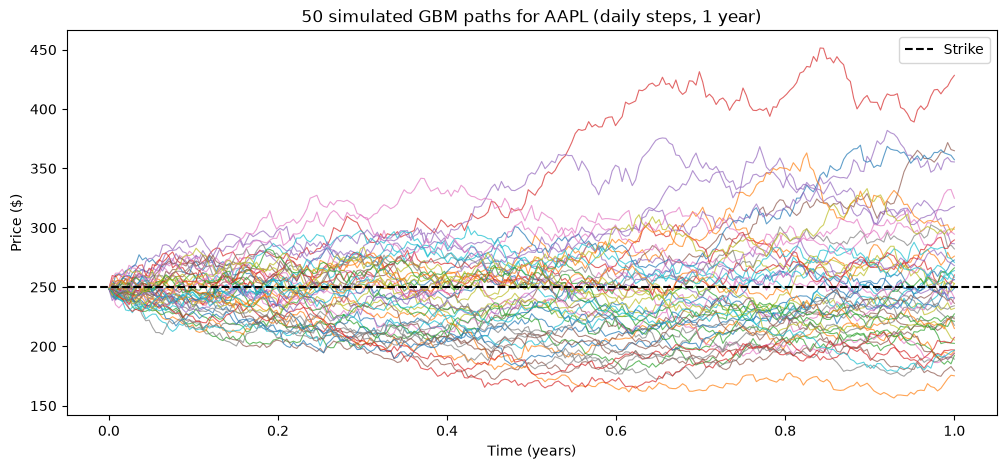

In [10]:
paths = simulate_gbm(S0, r, sigma, T, 252, 50)
t = np.linspace(0, T, 253)

plt.figure(figsize=(12, 5))
plt.plot(t, paths.T, linewidth=0.8, alpha=0.7)
plt.axhline(K, color='black', linestyle='--', label='Strike')
plt.title('50 simulated GBM paths for AAPL (daily steps, 1 year)')
plt.xlabel('Time (years)')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

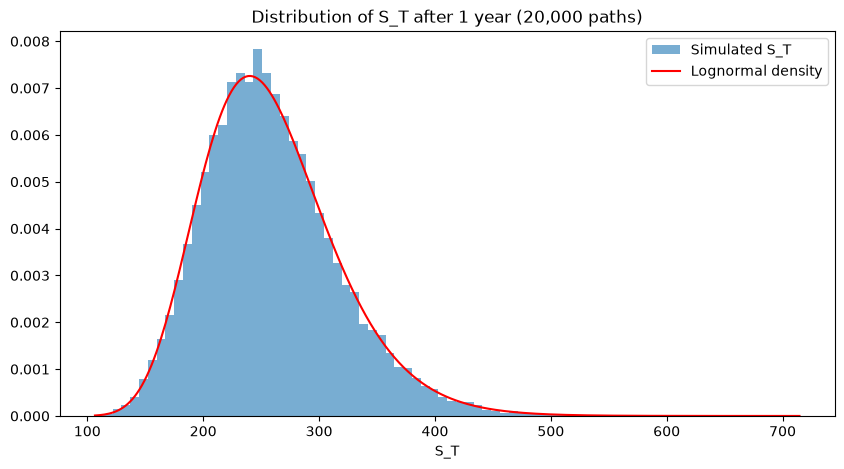

Mean of simulated S_T: 258.5
Theoretical mean S0*exp(rT): 258.76


In [11]:
# Check the terminal distribution against the lognormal density
paths = simulate_gbm(S0, r, sigma, T, 252, 20000)
ST = paths[:, -1]

x = np.linspace(ST.min(), ST.max(), 300)
mu_log = np.log(S0) + (r - 0.5 * sigma**2) * T
pdf = norm.pdf(np.log(x), mu_log, sigma * np.sqrt(T)) / x

plt.figure(figsize=(10, 5))
plt.hist(ST, bins=80, density=True, alpha=0.6, label='Simulated S_T')
plt.plot(x, pdf, 'r', label='Lognormal density')
plt.title('Distribution of S_T after 1 year (20,000 paths)')
plt.xlabel('S_T')
plt.legend()
plt.show()

print('Mean of simulated S_T:', round(ST.mean(), 2))
print('Theoretical mean S0*exp(rT):', round(S0 * np.exp(r * T), 2))

## 3. Monte Carlo pricing of the European options

A European payoff only depends on $S_T$, so I can sample $S_T$ directly without the intermediate steps. With $N$ samples of the discounted payoff $Y_i$:

$$\hat{V} = \frac{1}{N}\sum_{i=1}^N Y_i, \qquad \text{SE} = \frac{s_Y}{\sqrt{N}}, \qquad \text{95\% CI} = \hat{V} \pm 1.96\,\text{SE}$$

By the central limit theorem the error shrinks like $1/\sqrt{N}$, so 100 times more paths gives one more decimal place.

In [12]:
def mc_european(S0, K, T, r, sigma, n_paths, option='call'):
    Z = np.random.standard_normal(n_paths)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    if option == 'call':
        payoff = np.maximum(ST - K, 0)
    else:
        payoff = np.maximum(K - ST, 0)
    Y = np.exp(-r * T) * payoff
    price = Y.mean()
    se = Y.std(ddof=1) / np.sqrt(n_paths)
    return price, se

In [13]:
call_mc, call_se = mc_european(S0, K, T, r, sigma, 100000, 'call')
put_mc, put_se = mc_european(S0, K, T, r, sigma, 100000, 'put')

print(f'Call  MC: {call_mc:.4f} +/- {1.96*call_se:.4f}   BS: {call_bs:.4f}')
print(f'Put   MC: {put_mc:.4f} +/- {1.96*put_se:.4f}   BS: {put_bs:.4f}')

Call  MC: 25.9604 +/- 0.2453   BS: 26.1877
Put   MC: 17.8281 +/- 0.1587   BS: 17.7693


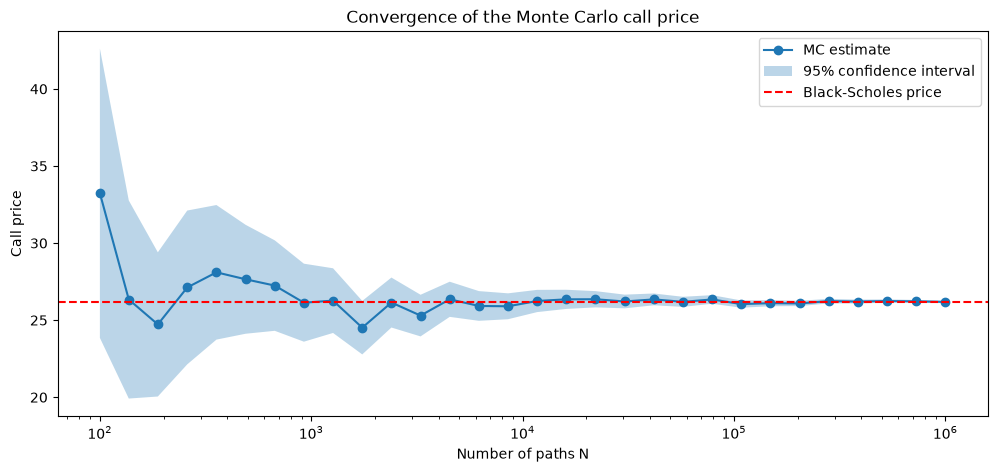

Number of estimates whose 95% CI contains the BS price: 30 out of 30


In [14]:
# Price the call with more and more paths
N_values = np.unique(np.logspace(2, 6, 30).astype(int))
estimates = []
errors = []

for N in N_values:
    price, se = mc_european(S0, K, T, r, sigma, N, 'call')
    estimates.append(price)
    errors.append(se)

estimates = np.array(estimates)
errors = np.array(errors)

plt.figure(figsize=(12, 5))
plt.plot(N_values, estimates, 'o-', label='MC estimate')
plt.fill_between(N_values, estimates - 1.96 * errors, estimates + 1.96 * errors, alpha=0.3, label='95% confidence interval')
plt.axhline(call_bs, color='red', linestyle='--', label='Black-Scholes price')
plt.xscale('log')
plt.title('Convergence of the Monte Carlo call price')
plt.xlabel('Number of paths N')
plt.ylabel('Call price')
plt.legend()
plt.show()

inside = np.abs(estimates - call_bs) <= 1.96 * errors
print('Number of estimates whose 95% CI contains the BS price:', inside.sum(), 'out of', len(N_values))

### Error rate on a log-log plot

One run at each $N$ is noisy, so I repeat the pricing 100 times at each $N$ and take the root mean squared error against the Black-Scholes price. If $\text{error} \approx c N^{-1/2}$ then $\log(\text{error}) = \log c - \tfrac{1}{2}\log N$, a straight line with slope $-0.5$.

In [15]:
N_grid = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
n_repeats = 100
rmse = []
mean_se = []

for N in N_grid:
    prices = []
    ses = []
    for i in range(n_repeats):
        price, se = mc_european(S0, K, T, r, sigma, N, 'call')
        prices.append(price)
        ses.append(se)
    rmse.append(np.sqrt(np.mean((np.array(prices) - call_bs)**2)))
    mean_se.append(np.mean(ses))

rmse = np.array(rmse)
mean_se = np.array(mean_se)

# Fit a straight line in log-log space
slope, intercept = np.polyfit(np.log(N_grid), np.log(rmse), 1)
print('Fitted slope of log(RMSE) vs log(N):', round(slope, 3))

Fitted slope of log(RMSE) vs log(N): -0.496


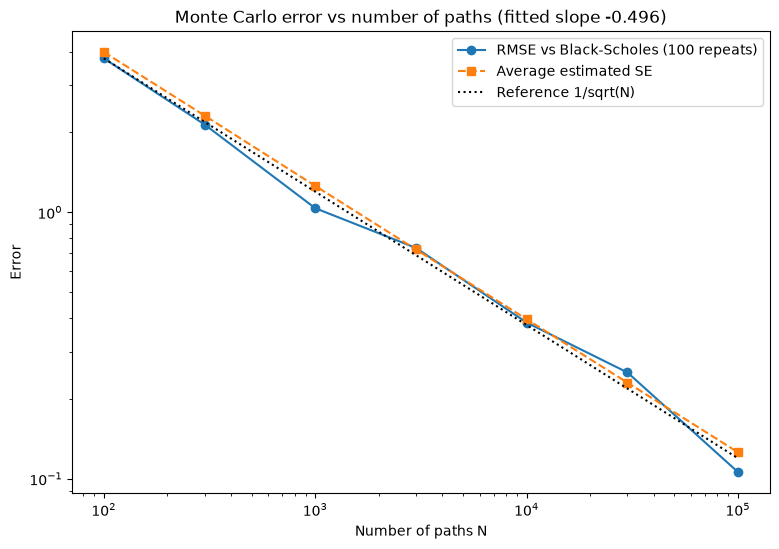

In [16]:
plt.figure(figsize=(9, 6))
plt.loglog(N_grid, rmse, 'o-', label='RMSE vs Black-Scholes (100 repeats)')
plt.loglog(N_grid, mean_se, 's--', label='Average estimated SE')
plt.loglog(N_grid, rmse[0] * np.sqrt(N_grid[0] / N_grid), 'k:', label='Reference 1/sqrt(N)')
plt.title(f'Monte Carlo error vs number of paths (fitted slope {slope:.3f})')
plt.xlabel('Number of paths N')
plt.ylabel('Error')
plt.legend()
plt.show()

## 4. Variance reduction

Since the error is $\sigma_Y/\sqrt{N}$, the other way to reduce it is to reduce $\sigma_Y$. I compare everything with the same budget of $N = 100{,}000$ simulated payoffs.

**Antithetic variates.** For every $Z$ also use $-Z$. The two payoffs are negatively correlated, so their average has lower variance:

$$\hat{V}_{AV} = \frac{1}{N/2}\sum_{i=1}^{N/2} \frac{Y(Z_i) + Y(-Z_i)}{2}$$

**Control variate.** Use a variable $X$ with a known mean that is correlated with the payoff. Here $X = e^{-rT}S_T$, whose mean is exactly $S_0$:

$$\hat{V}_{CV} = \frac{1}{N}\sum_{i=1}^N \left(Y_i - b\,(X_i - S_0)\right), \qquad b^* = \frac{\text{Cov}(Y, X)}{\text{Var}(X)}$$

The variance is reduced by a factor of $1 - \rho_{XY}^2$.

In [17]:
def mc_antithetic(S0, K, T, r, sigma, n_paths):
    Z = np.random.standard_normal(n_paths // 2)
    ST_plus = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    ST_minus = S0 * np.exp((r - 0.5 * sigma**2) * T - sigma * np.sqrt(T) * Z)
    Y = np.exp(-r * T) * 0.5 * (np.maximum(ST_plus - K, 0) + np.maximum(ST_minus - K, 0))
    return Y.mean(), Y.std(ddof=1) / np.sqrt(len(Y))

def mc_control_variate(S0, K, T, r, sigma, n_paths):
    Z = np.random.standard_normal(n_paths)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    Y = np.exp(-r * T) * np.maximum(ST - K, 0)
    X = np.exp(-r * T) * ST           # control, E[X] = S0
    b = np.cov(Y, X)[0, 1] / np.var(X, ddof=1)
    Y_cv = Y - b * (X - S0)
    return Y_cv.mean(), Y_cv.std(ddof=1) / np.sqrt(n_paths), np.corrcoef(Y, X)[0, 1]

In [18]:
N = 100000
plain_price, plain_se = mc_european(S0, K, T, r, sigma, N, 'call')
av_price, av_se = mc_antithetic(S0, K, T, r, sigma, N)
cv_price, cv_se, rho = mc_control_variate(S0, K, T, r, sigma, N)

print('Correlation between payoff and control:', round(rho, 4))
print()
print(f"{'Method':<20}{'Price':>10}{'SE':>10}{'Var reduction':>16}")
print(f"{'Black-Scholes':<20}{call_bs:>10.4f}")
for name, p, s in [('Plain MC', plain_price, plain_se), ('Antithetic', av_price, av_se), ('Control variate', cv_price, cv_se)]:
    print(f'{name:<20}{p:>10.4f}{s:>10.4f}{(plain_se / s)**2:>15.2f}x')

Correlation between payoff and control: 0.9155

Method                   Price        SE   Var reduction
Black-Scholes          26.1877
Plain MC               26.2381    0.1255           1.00x
Antithetic             26.1562    0.0946           1.76x
Control variate        26.1459    0.0505           6.18x


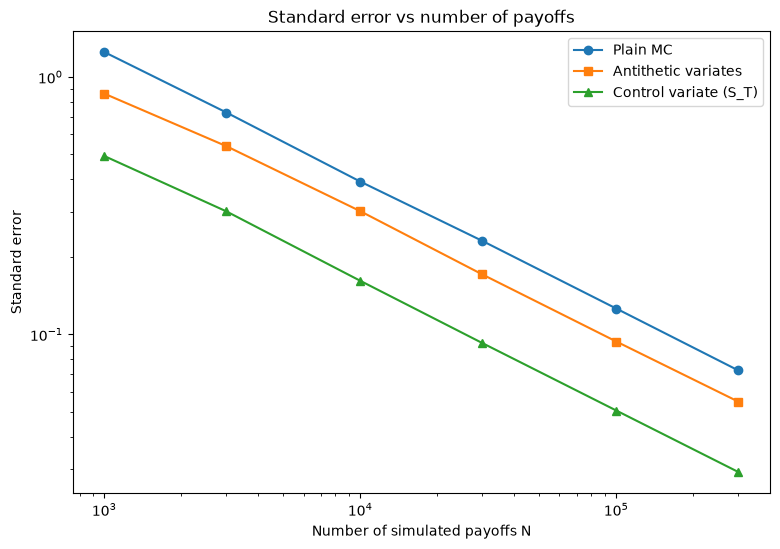

In [19]:
# Standard error of each method as N grows
N_grid = np.array([1000, 3000, 10000, 30000, 100000, 300000])
se_plain, se_av, se_cv = [], [], []
for N in N_grid:
    se_plain.append(mc_european(S0, K, T, r, sigma, N, 'call')[1])
    se_av.append(mc_antithetic(S0, K, T, r, sigma, N)[1])
    se_cv.append(mc_control_variate(S0, K, T, r, sigma, N)[1])

plt.figure(figsize=(9, 6))
plt.loglog(N_grid, se_plain, 'o-', label='Plain MC')
plt.loglog(N_grid, se_av, 's-', label='Antithetic variates')
plt.loglog(N_grid, se_cv, '^-', label='Control variate (S_T)')
plt.title('Standard error vs number of payoffs')
plt.xlabel('Number of simulated payoffs N')
plt.ylabel('Standard error')
plt.legend()
plt.show()

## 5. Options without a simple formula

### Asian (average-price) call

The payoff depends on the arithmetic average of the price over the life of the option, here at the 252 daily closes:

$$\text{payoff} = \max\left(\bar{S} - K, 0\right), \qquad \bar{S} = \frac{1}{n}\sum_{i=1}^{n} S_{t_i}$$

A sum of lognormals is not lognormal, so there is no closed-form price. The **geometric** average $G = \left(\prod S_{t_i}\right)^{1/n}$ *is* lognormal, with

$$\ln G \sim N\left(\ln S_0 + \left(r - \tfrac{1}{2}\sigma^2\right)T\frac{n+1}{2n},\ \ \sigma^2 T\frac{(n+1)(2n+1)}{6n^2}\right)$$

so its price has a Black-Scholes style formula. I use it twice: first to check the simulation, then as a control variate for the arithmetic option (the two averages are almost perfectly correlated).

In [20]:
def geometric_asian_call(S0, K, T, r, sigma, n):
    mu = np.log(S0) + (r - 0.5 * sigma**2) * T * (n + 1) / (2 * n)
    var = sigma**2 * T * (n + 1) * (2 * n + 1) / (6 * n**2)
    d1 = (mu - np.log(K) + var) / np.sqrt(var)
    d2 = d1 - np.sqrt(var)
    return np.exp(-r * T) * (np.exp(mu + 0.5 * var) * norm.cdf(d1) - K * norm.cdf(d2))

In [21]:
n_steps = 252
n_paths = 100000
paths = simulate_gbm(S0, r, sigma, T, n_steps, n_paths)
monitored = paths[:, 1:]   # the 252 daily closes (not S0)

arith_avg = monitored.mean(axis=1)
geo_avg = np.exp(np.log(monitored).mean(axis=1))

Y_arith = np.exp(-r * T) * np.maximum(arith_avg - K, 0)
Y_geo = np.exp(-r * T) * np.maximum(geo_avg - K, 0)

geo_exact = geometric_asian_call(S0, K, T, r, sigma, n_steps)
print(f'Geometric Asian  MC: {Y_geo.mean():.4f} +/- {1.96*Y_geo.std(ddof=1)/np.sqrt(n_paths):.4f}   exact: {geo_exact:.4f}')

Geometric Asian  MC: 13.6708 +/- 0.1270   exact: 13.7356


In [22]:
# Arithmetic Asian: plain MC and with the geometric option as control variate
asian_plain = Y_arith.mean()
asian_plain_se = Y_arith.std(ddof=1) / np.sqrt(n_paths)

b = np.cov(Y_arith, Y_geo)[0, 1] / np.var(Y_geo, ddof=1)
Y_asian_cv = Y_arith - b * (Y_geo - geo_exact)
asian_cv = Y_asian_cv.mean()
asian_cv_se = Y_asian_cv.std(ddof=1) / np.sqrt(n_paths)

print('Correlation of arithmetic and geometric payoffs:', round(np.corrcoef(Y_arith, Y_geo)[0, 1], 5))
print(f'Arithmetic Asian plain MC:      {asian_plain:.4f}  (SE {asian_plain_se:.4f})')
print(f'Arithmetic Asian with control:  {asian_cv:.4f}  (SE {asian_cv_se:.5f})')
print(f'Variance reduction: {(asian_plain_se / asian_cv_se)**2:.0f}x')
print(f'European call for comparison:   {call_bs:.4f}')

Correlation of arithmetic and geometric payoffs: 0.99953
Arithmetic Asian plain MC:      14.2824  (SE 0.0674)
Arithmetic Asian with control:  14.3498  (SE 0.00207)
Variance reduction: 1063x
European call for comparison:   26.1877


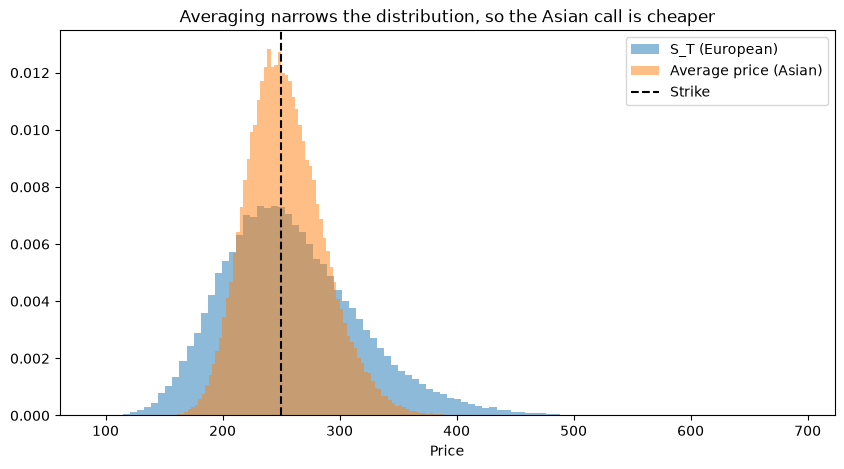

In [23]:
plt.figure(figsize=(10, 5))
plt.hist(paths[:, -1], bins=100, alpha=0.5, density=True, label='S_T (European)')
plt.hist(arith_avg, bins=100, alpha=0.5, density=True, label='Average price (Asian)')
plt.axvline(K, color='black', linestyle='--', label='Strike')
plt.title('Averaging narrows the distribution, so the Asian call is cheaper')
plt.xlabel('Price')
plt.legend()
plt.show()

### Up-and-out barrier call

This is a normal call that is cancelled (pays nothing) if the price ever reaches the barrier $B$ above the spot:

$$\text{payoff} = \max(S_T - K, 0)\ \mathbb{1}\left\{\max_i S_{t_i} < B\right\}$$

There is a closed form when the barrier is watched continuously, but with daily monitoring there isn't a simple one. With simulation it is just one extra line: check the path maximum. I use the same simulated paths for every barrier level so the curve is smooth.

In [24]:
B = 1.3 * S0
path_max = paths.max(axis=1)
ST = paths[:, -1]

knocked_out = path_max >= B
Y_barrier = np.exp(-r * T) * np.maximum(ST - K, 0) * (~knocked_out)
barrier_price = Y_barrier.mean()
barrier_se = Y_barrier.std(ddof=1) / np.sqrt(n_paths)

print(f'Barrier level B = {B:.2f}')
print(f'Up-and-out call: {barrier_price:.4f} +/- {1.96*barrier_se:.4f}')
print(f'Fraction of paths knocked out: {knocked_out.mean():.3f}')
print(f'Vanilla call (BS): {call_bs:.4f}')

Barrier level B = 323.20
Up-and-out call: 6.8451 +/- 0.0882
Fraction of paths knocked out: 0.244
Vanilla call (BS): 26.1877


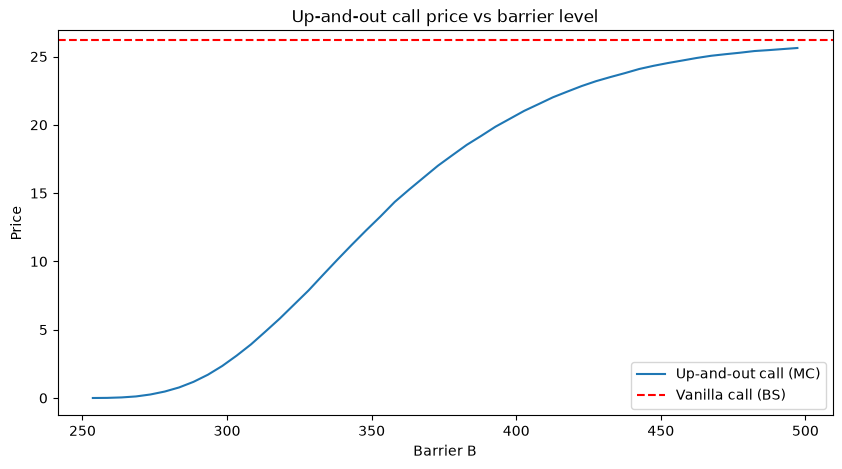

In [25]:
barriers = np.linspace(1.02, 2.0, 50) * S0
barrier_prices = []
for b_level in barriers:
    alive = path_max < b_level
    barrier_prices.append(np.mean(np.exp(-r * T) * np.maximum(ST - K, 0) * alive))

plt.figure(figsize=(10, 5))
plt.plot(barriers, barrier_prices, label='Up-and-out call (MC)')
plt.axhline(call_bs, color='red', linestyle='--', label='Vanilla call (BS)')
plt.title('Up-and-out call price vs barrier level')
plt.xlabel('Barrier B')
plt.ylabel('Price')
plt.legend()
plt.show()

## 6. Greeks: finite differences vs analytic

For the call the analytic Greeks are

$$\Delta = \frac{\partial C}{\partial S} = N(d_1), \qquad \Gamma = \frac{\partial^2 C}{\partial S^2} = \frac{\phi(d_1)}{S\sigma\sqrt{T}}$$

and central finite differences with bump size $h$ give

$$\Delta \approx \frac{V(S+h) - V(S-h)}{2h}, \qquad \Gamma \approx \frac{V(S+h) - 2V(S) + V(S-h)}{h^2}$$

both with $O(h^2)$ truncation error. For the Monte Carlo version I use the same random numbers $Z$ for all three prices (common random numbers), otherwise the noise in each price would swamp the small difference.

In [26]:
def bs_delta(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return norm.cdf(d1)

def bs_gamma(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return norm.pdf(d1) / (S * sigma * np.sqrt(T))

def mc_call_fixed_Z(S, K, T, r, sigma, Z):
    ST = S * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    return np.mean(np.exp(-r * T) * np.maximum(ST - K, 0))

In [27]:
h = 1.0
Z = np.random.standard_normal(1000000)

# Finite differences on the BS formula
delta_fd = (bs_call(S0 + h, K, T, r, sigma) - bs_call(S0 - h, K, T, r, sigma)) / (2 * h)
gamma_fd = (bs_call(S0 + h, K, T, r, sigma) - 2 * call_bs + bs_call(S0 - h, K, T, r, sigma)) / h**2

# Finite differences on the MC price with common random numbers
up = mc_call_fixed_Z(S0 + h, K, T, r, sigma, Z)
mid = mc_call_fixed_Z(S0, K, T, r, sigma, Z)
down = mc_call_fixed_Z(S0 - h, K, T, r, sigma, Z)
delta_mc = (up - down) / (2 * h)
gamma_mc = (up - 2 * mid + down) / h**2

print(f"{'':<22}{'Delta':>10}{'Gamma':>10}")
print(f"{'Analytic':<22}{bs_delta(S0, K, T, r, sigma):>10.5f}{bs_gamma(S0, K, T, r, sigma):>10.5f}")
print(f"{'FD on BS (h=1)':<22}{delta_fd:>10.5f}{gamma_fd:>10.5f}")
print(f"{'FD on MC (h=1, 1M)':<22}{delta_mc:>10.5f}{gamma_mc:>10.5f}")

                           Delta     Gamma
Analytic                 0.60485   0.00694
FD on BS (h=1)           0.60484   0.00694
FD on MC (h=1, 1M)       0.60439   0.00686


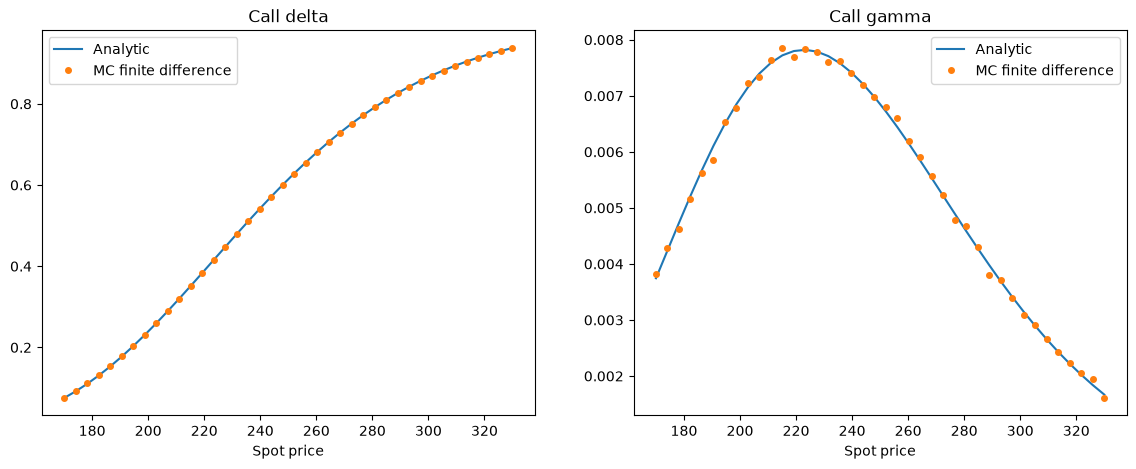

In [28]:
# Delta and gamma across spot prices
spots = np.linspace(170, 330, 40)
Z = np.random.standard_normal(200000)
h = 2.0

delta_mc_curve = []
gamma_mc_curve = []
for S in spots:
    up = mc_call_fixed_Z(S + h, K, T, r, sigma, Z)
    mid = mc_call_fixed_Z(S, K, T, r, sigma, Z)
    down = mc_call_fixed_Z(S - h, K, T, r, sigma, Z)
    delta_mc_curve.append((up - down) / (2 * h))
    gamma_mc_curve.append((up - 2 * mid + down) / h**2)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(spots, bs_delta(spots, K, T, r, sigma), label='Analytic')
ax[0].plot(spots, delta_mc_curve, 'o', markersize=4, label='MC finite difference')
ax[0].set_title('Call delta')
ax[0].set_xlabel('Spot price')
ax[0].legend()
ax[1].plot(spots, bs_gamma(spots, K, T, r, sigma), label='Analytic')
ax[1].plot(spots, gamma_mc_curve, 'o', markersize=4, label='MC finite difference')
ax[1].set_title('Call gamma')
ax[1].set_xlabel('Spot price')
ax[1].legend()
plt.show()

### Choosing the bump size

On the exact formula a smaller $h$ should be better because the truncation error is $O(h^2)$, but if $h$ is too small floating-point rounding takes over (subtracting two nearly equal numbers). Gamma divides by $h^2$ so it breaks down much sooner.

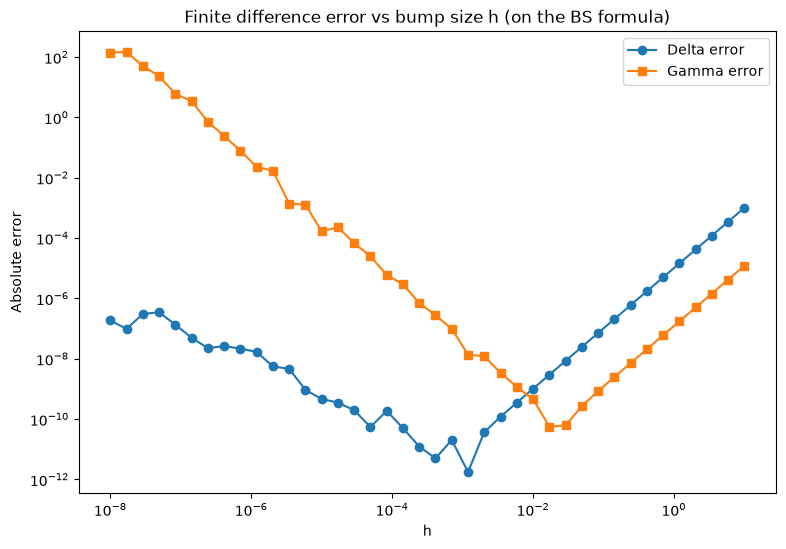

Best h for delta: 0.0011937766417144382  error: 1.7612578062653483e-12
Best h for gamma: 0.017012542798525893  error: 5.645977348839315e-11


In [29]:
h_values = np.logspace(-8, 1, 40)
delta_true = bs_delta(S0, K, T, r, sigma)
gamma_true = bs_gamma(S0, K, T, r, sigma)

delta_err = []
gamma_err = []
for h in h_values:
    up = bs_call(S0 + h, K, T, r, sigma)
    down = bs_call(S0 - h, K, T, r, sigma)
    delta_err.append(abs((up - down) / (2 * h) - delta_true))
    gamma_err.append(abs((up - 2 * call_bs + down) / h**2 - gamma_true))

plt.figure(figsize=(9, 6))
plt.loglog(h_values, delta_err, 'o-', label='Delta error')
plt.loglog(h_values, gamma_err, 's-', label='Gamma error')
plt.title('Finite difference error vs bump size h (on the BS formula)')
plt.xlabel('h')
plt.ylabel('Absolute error')
plt.legend()
plt.show()

print('Best h for delta:', h_values[np.argmin(delta_err)], ' error:', min(delta_err))
print('Best h for gamma:', h_values[np.argmin(gamma_err)], ' error:', min(gamma_err))

## Summary

- The Black-Scholes prices satisfy put-call parity to floating-point precision.
- Monte Carlo converges to the Black-Scholes price with error proportional to $1/\sqrt{N}$, which is slow: halving the error costs four times as many paths.
- Antithetic variates and a control variate cut the standard error for the same number of paths, which is the same as running many more paths.
- For the Asian and barrier options there is no simple formula, but the simulation code barely changes, which is the main reason Monte Carlo is used in practice.
- Finite differences match the analytic Greeks when the bump size is chosen sensibly and the MC version uses common random numbers.